# Homework 2

Repository: [https://github.com/courbel/DATA-37711](https://github.com/courbel/DATA-37711)

Homework 2 code: [https://github.com/courbel/DATA-37711/tree/main/homework_2](https://github.com/courbel/DATA-37711/tree/main/homework_2)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             brier_score_loss, log_loss, accuracy_score)
import category_encoders as ce

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
device = "cpu"

## Problem 1

### (a) Link function

Write $g(x) = (g_1(x), g_2(x)) \in \mathbb{R}^2$. The mean can be any real number, so use the identity link for it; the standard deviation must be positive, so pass the second output through a positive function such as softplus (or $\exp$):

$$f_\mu(x) = g_1(x), \qquad f_\sigma(x) = \operatorname{softplus}(g_2(x)) + \varepsilon = \log\big(1 + e^{g_2(x)}\big) + \varepsilon,$$

with a small $\varepsilon > 0$ (I use $10^{-3}$) for numerical stability. Softplus is smooth, strictly positive, and grows only linearly, so it is more stable to train than $\exp$.

### (b) Loss function

Under $Y \mid X \sim \mathcal{N}(f_\mu(X), f_\sigma(X)^2)$, the natural loss is the negative log-likelihood (the log score, a proper scoring rule). For one observation,

$$L(y, x) = -\log p(y \mid x) = \log f_\sigma(x) + \frac{\big(y - f_\mu(x)\big)^2}{2 f_\sigma(x)^2} + \tfrac12 \log(2\pi),$$

and we minimize the average over the training set, $\frac1n \sum_{i=1}^n L(y_i, x_i)$ (the constant can be dropped). If $f_\sigma$ were constant, this reduces to the squared-error loss.

### (c) MLP with a conditional mean and standard deviation

Split: 70% train, 15% validation (early stopping), 15% test. The features are already standardized.

Baselines the MLP should beat (all evaluated with the same Gaussian NLL):
1. **Constant:** $\mu$ and $\sigma$ are the training mean and standard deviation of trip duration (ignores $X$).
2. **Linear, homoscedastic:** $\mu(x)$ from linear regression, constant $\sigma$ equal to the training residual standard deviation.

In [2]:
taxi = pd.read_parquet("data/taxi_trips.parquet")
target = "trip_duration"
features = [c for c in taxi.columns if c != target]
print(taxi.shape, features)

X = taxi[features].to_numpy(np.float32)
y = taxi[target].to_numpy(np.float32)
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.3, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=SEED)
print(len(y_tr), len(y_va), len(y_te))

def gaussian_nll(y, mu, sigma):
    return np.mean(np.log(sigma) + 0.5 * ((y - mu) / sigma) ** 2 + 0.5 * np.log(2 * np.pi))

def report(name, mu, sigma):
    return {"model": name, "test NLL": gaussian_nll(y_te, mu, sigma),
            "test RMSE": np.sqrt(mean_squared_error(y_te, mu))}

results = []
# Baseline 1: constant mean and sd
results.append(report("Constant mean/sd", np.full_like(y_te, y_tr.mean()), np.full_like(y_te, y_tr.std())))
# Baseline 2: linear mean, constant sd
lin = LinearRegression().fit(X_tr, y_tr)
lin_sd = np.std(y_tr - lin.predict(X_tr))
results.append(report("Linear mean, constant sd", lin.predict(X_te), np.full_like(y_te, lin_sd)))
pd.DataFrame(results)

(523554, 8) ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'min_of_day', 'day_of_week', 'day_of_year']
366487 78533 78534


,model,test NLL,test RMSE
0,Constant mean/sd,3.458678,7.687516
1,"Linear mean, constant sd",3.430432,7.473315


In [3]:
class GaussianMLP(nn.Module):
    def __init__(self, d_in, d_hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden), nn.ReLU(),
            nn.Linear(d_hidden, d_hidden), nn.ReLU(),
            nn.Linear(d_hidden, 2),
        )
    def forward(self, x):
        out = self.net(x)
        mu = out[:, 0]
        sigma = F.softplus(out[:, 1]) + 1e-3   # link from (a)
        return mu, sigma

def nll_loss(y, mu, sigma):                    # loss from (b), constant dropped
    return (torch.log(sigma) + 0.5 * ((y - mu) / sigma) ** 2).mean()

Xtr_t, ytr_t = torch.tensor(X_tr), torch.tensor(y_tr)
Xva_t, yva_t = torch.tensor(X_va), torch.tensor(y_va)
Xte_t = torch.tensor(X_te)

torch.manual_seed(SEED)
taxi_model = GaussianMLP(len(features))
opt = torch.optim.Adam(taxi_model.parameters(), lr=1e-3)
batch_size, max_epochs, patience = 1024, 40, 4
best_val, best_state, bad = np.inf, None, 0
history = []
for epoch in range(max_epochs):
    taxi_model.train()
    perm = torch.randperm(len(ytr_t))
    for i in range(0, len(perm), batch_size):
        idx = perm[i:i + batch_size]
        mu, sigma = taxi_model(Xtr_t[idx])
        loss = nll_loss(ytr_t[idx], mu, sigma)
        opt.zero_grad(); loss.backward(); opt.step()
    taxi_model.eval()
    with torch.no_grad():
        val_loss = nll_loss(yva_t, *taxi_model(Xva_t)).item()
    history.append(val_loss)
    if val_loss < best_val - 1e-4:
        best_val, best_state, bad = val_loss, {k: v.clone() for k, v in taxi_model.state_dict().items()}, 0
    else:
        bad += 1
        if bad >= patience:
            break
taxi_model.load_state_dict(best_state)
print(f"stopped after {epoch + 1} epochs, best val NLL (no constant) = {best_val:.4f}")

with torch.no_grad():
    mu_te, sigma_te = (t.numpy() for t in taxi_model(Xte_t))
results.append(report("MLP (mean + sd)", mu_te, sigma_te))
pd.DataFrame(results)

stopped after 28 epochs, best val NLL (no constant) = 1.7964


,model,test NLL,test RMSE
0,Constant mean/sd,3.458678,7.687516
1,"Linear mean, constant sd",3.430432,7.473315
2,MLP (mean + sd),2.657428,4.011487


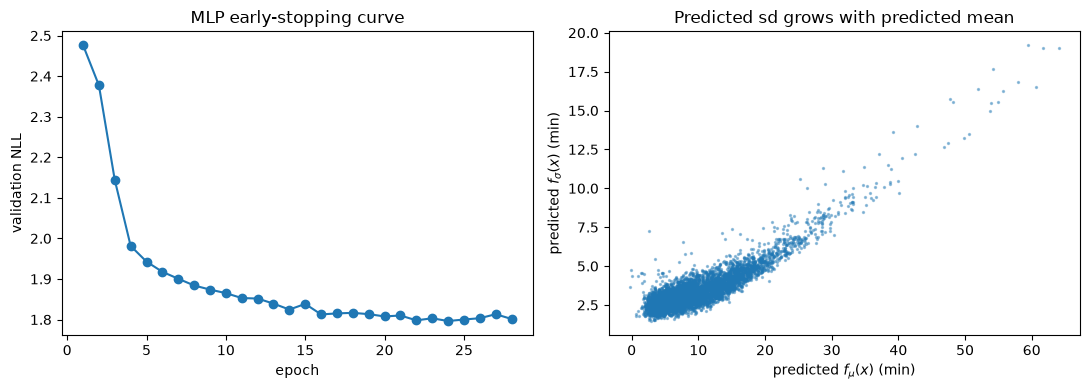

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(1, len(history) + 1), history, marker="o")
axes[0].set(xlabel="epoch", ylabel="validation NLL", title="MLP early-stopping curve")
axes[1].scatter(mu_te[:5000], sigma_te[:5000], s=2, alpha=0.4)
axes[1].set(xlabel=r"predicted $f_\mu(x)$ (min)", ylabel=r"predicted $f_\sigma(x)$ (min)",
            title="Predicted sd grows with predicted mean")
plt.tight_layout(); plt.show()

The MLP beats both baselines on test NLL and RMSE. It also learns heteroscedastic noise: longer predicted trips get larger predicted standard deviations, which a constant-$\sigma$ model cannot capture.

### (d) Probability that a trip takes less than 45 minutes

Under the fitted model $Y \mid X = x \sim \mathcal{N}(f_\mu(x), f_\sigma(x)^2)$, so

$$P(Y < 45 \mid X = x) = \Phi\!\left(\frac{45 - f_\mu(x)}{f_\sigma(x)}\right),$$

where $\Phi$ is the standard normal CDF. We plug in the network's two outputs for each trip.

### (e) Evaluation on the test set

The label is $\mathbb{1}\{y < 45\}$. I report the Brier score and log-loss (proper scoring rules) and accuracy at threshold 0.5, next to the same probabilities from the two baselines.

In [5]:
z_te = (y_te < 45).astype(int)
print(f"fraction of test trips under 45 min: {z_te.mean():.4f}")

def prob_report(name, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {"model": name, "Brier": brier_score_loss(z_te, p), "log-loss": log_loss(z_te, p),
            "accuracy @0.5": accuracy_score(z_te, (p >= 0.5).astype(int))}

prob_results = [
    prob_report("Constant mean/sd", norm.cdf((45 - y_tr.mean()) / y_tr.std()) * np.ones_like(y_te)),
    prob_report("Linear mean, constant sd", norm.cdf((45 - lin.predict(X_te)) / lin_sd)),
    prob_report("MLP (mean + sd)", norm.cdf((45 - mu_te) / sigma_te)),
]
pd.DataFrame(prob_results)

fraction of test trips under 45 min: 0.9957


,model,Brier,log-loss,accuracy @0.5
0,Constant mean/sd,0.004317,0.053218,0.995683
1,"Linear mean, constant sd",0.004317,0.044501,0.995683
2,MLP (mean + sd),0.003306,0.018382,0.995925


Since more than 99% of trips are under 45 minutes, accuracy at 0.5 is close to what you get by always predicting "under 45", so it barely separates the models. The proper scoring rules are more informative: the MLP has the lowest Brier score and log-loss, because its input-dependent $f_\sigma$ gives long trips a realistic chance of exceeding 45 minutes. The Gaussian assumption is only approximate here (trip durations are positive and right-skewed), so these probabilities could be improved further with e.g. a log-normal model, but the normal model is what the question asks for.

## Problem 2

### (a) Cardinality and splits

In [6]:
retail = pd.read_csv("data/retail.csv")
retail["StockCode"] = retail["StockCode"].astype(str).astype("category")
retail["CustomerID"] = retail["CustomerID"].astype(int).astype(str).astype("category")
cat_cols = ["StockCode", "CustomerID"]
print(retail.shape)
print(retail[cat_cols].nunique())
print(retail["Quantity"].describe())

(397924, 3)
StockCode     3665
CustomerID    4339
dtype: int64
count    397924.000000
mean         13.021823
std         180.420210
min           1.000000
25%           2.000000
50%           6.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64


`StockCode` has about 3.7k levels and `CustomerID` about 4.3k, so a one-hot encoding would have about 8,000 sparse columns for about 400k rows. That is feasible in memory with a sparse matrix, but awkward: most levels appear in few rows, so a separate coefficient per level is noisy, and new levels in the test set get no information. This suggests a dense, low-dimensional encoding instead: target encoding (one number per level) or learned embeddings.

**Target and loss.** `Quantity` is very heavy-tailed (median 6, max 80,995). I model $\log(1 + \text{Quantity})$ with squared-error loss, which corresponds to a multiplicative / log-normal noise model and prevents a few huge orders from dominating training. All models are compared on test MSE on the log scale; I also report MAE on the original scale.

Split: 70% train, 15% validation (early stopping), 15% test.

In [7]:
r_tr, r_tmp = train_test_split(retail, test_size=0.3, random_state=SEED)
r_va, r_te = train_test_split(r_tmp, test_size=0.5, random_state=SEED)
ly_tr, ly_va, ly_te = (np.log1p(d["Quantity"].to_numpy(np.float32)) for d in (r_tr, r_va, r_te))
print(len(r_tr), len(r_va), len(r_te))
for c in cat_cols:
    seen = set(r_tr[c])
    print(f"{c}: share of test rows with a level unseen in training = {(~r_te[c].isin(seen)).mean():.4f}")

retail_results = []
def retail_report(name, pred_log):
    return {"model": name, "test MSE (log1p scale)": mean_squared_error(ly_te, pred_log),
            "test MAE (original scale)": mean_absolute_error(r_te["Quantity"], np.expm1(pred_log))}

retail_results.append(retail_report("Baseline: training mean", np.full_like(ly_te, ly_tr.mean())))
pd.DataFrame(retail_results)

278546 59689 59689
StockCode: share of test rows with a level unseen in training = 0.0005
CustomerID: share of test rows with a level unseen in training = 0.0004


,model,test MSE (log1p scale),test MAE (original scale)
0,Baseline: training mean,1.014389,10.646861


### (b) Target encoding

`TargetEncoder` (from `category_encoders`) replaces each level by a smoothed mean of the (log) target over the training rows with that level; unseen levels get the global mean. On top of the two encoded columns I fit a histogram gradient boosting regressor with squared-error loss on the log target (validation set used for early stopping).

In [8]:
te = ce.TargetEncoder(cols=cat_cols, smoothing=10)
te.fit(r_tr[cat_cols], ly_tr)
T_tr, T_va, T_te = (te.transform(d[cat_cols]).to_numpy(np.float32) for d in (r_tr, r_va, r_te))

gbm = HistGradientBoostingRegressor(loss="squared_error", max_iter=500, early_stopping=True,
                                    validation_fraction=0.15, random_state=SEED)
gbm.fit(T_tr, ly_tr)
retail_results.append(retail_report("Target encoding + GBM", gbm.predict(T_te)))
pd.DataFrame(retail_results)

,model,test MSE (log1p scale),test MAE (original scale)
0,Baseline: training mean,1.014389,10.646861
1,Target encoding + GBM,0.337242,7.025133


### (c) Embedding network

Each feature gets its own `nn.Embedding` with dimension 16 (index 0 is reserved for levels not seen in training). The two embeddings are concatenated and passed through an MLP (32 → 64 → 1). Trained with Adam on MSE of the log target, with early stopping on validation MSE.

### (d) Combined model

Same network, but the two (standardized) target-encoded features are concatenated to the embeddings before the MLP.

In [9]:
# integer codes for each feature, 0 = unseen in training
codes = {}
for c in cat_cols:
    levels = {v: i + 1 for i, v in enumerate(r_tr[c].unique())}
    codes[c] = [torch.tensor(d[c].astype(str).map(levels).fillna(0).astype(int).to_numpy()) for d in (r_tr, r_va, r_te)]
idx_tr, idx_va, idx_te = (torch.stack([codes[c][k] for c in cat_cols], dim=1) for k in range(3))
n_levels = [int(codes[c][0].max()) + 1 for c in cat_cols]

t_mean, t_std = T_tr.mean(0), T_tr.std(0)
Ttr_t, Tva_t, Tte_t = (torch.tensor((T - t_mean) / t_std) for T in (T_tr, T_va, T_te))
lytr_t, lyva_t = torch.tensor(ly_tr), torch.tensor(ly_va)

class EmbeddingNet(nn.Module):
    def __init__(self, n_levels, emb_dim=16, n_extra=0, hidden=64):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n, emb_dim) for n in n_levels])
        self.mlp = nn.Sequential(nn.Linear(emb_dim * len(n_levels) + n_extra, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 1))
    def forward(self, idx, extra=None):
        h = [emb(idx[:, j]) for j, emb in enumerate(self.embs)]
        if extra is not None:
            h.append(extra)
        return self.mlp(torch.cat(h, dim=1)).squeeze(1)

def train_embedding_net(use_te, max_epochs=80, patience=3, batch_size=1024, lr=1e-3):
    torch.manual_seed(SEED)
    model = EmbeddingNet(n_levels, n_extra=2 if use_te else 0)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    extra = lambda T: T if use_te else None
    best_val, best_state, bad = np.inf, None, 0
    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(len(lytr_t))
        for i in range(0, len(perm), batch_size):
            b = perm[i:i + batch_size]
            loss = F.mse_loss(model(idx_tr[b], extra(Ttr_t[b])), lytr_t[b])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            val = F.mse_loss(model(idx_va, extra(Tva_t)), lyva_t).item()
        if val < best_val - 1e-4:
            best_val, best_state, bad = val, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred = model(idx_te, extra(Tte_t)).numpy()
    print(f"use_te={use_te}: {epoch + 1} epochs, best val MSE = {best_val:.4f}")
    return model, pred

emb_model, emb_pred = train_embedding_net(use_te=False)
retail_results.append(retail_report("Embeddings NN", emb_pred))
comb_model, comb_pred = train_embedding_net(use_te=True)
retail_results.append(retail_report("Embeddings + target encoding NN", comb_pred))
pd.DataFrame(retail_results)

use_te=False: 48 epochs, best val MSE = 0.2847


use_te=True: 36 epochs, best val MSE = 0.2827


,model,test MSE (log1p scale),test MAE (original scale)
0,Baseline: training mean,1.014389,10.646861
1,Target encoding + GBM,0.337242,7.025133
2,Embeddings NN,0.294188,6.484771
3,Embeddings + target encoding NN,0.291928,6.480045


### (e) Discussion

In [10]:
# Where do the models differ? Test MSE split by how often the StockCode appears in training.
counts = r_tr["StockCode"].value_counts()
freq = r_te["StockCode"].astype(str).map(counts).fillna(0).to_numpy()
bins = pd.cut(freq, [-1, 0, 20, 200, np.inf], labels=["unseen", "1-20", "21-200", ">200"])
preds = {"Target enc. + GBM": gbm.predict(T_te), "Embeddings": emb_pred, "Emb. + TE": comb_pred}
pd.DataFrame({name: pd.Series((ly_te - p) ** 2).groupby(bins, observed=True).mean() for name, p in preds.items()}
             ).assign(n_test_rows=pd.Series(bins).value_counts())

,Target enc. + GBM,Embeddings,Emb. + TE,n_test_rows
unseen,0.489154,1.221503,0.365995,30
1-20,0.477749,0.359510,0.357595,2291
21-200,0.335378,0.290617,0.290685,30599
>200,0.327178,0.291639,0.287645,26769


**Comparison.** All three models beat the training-mean baseline (test MSE 1.01 on the log scale) by a wide margin. The embedding network (about 0.294) beats target encoding + GBM (about 0.337), and combining embeddings with target-encoded features is the best of the three (about 0.292), though only slightly better than embeddings alone. The same ranking holds for MAE on the original scale.

**What the embedding layer is doing.** An embedding is a lookup table: each `StockCode` and each `CustomerID` gets its own learned vector in $\mathbb{R}^{16}$. Mathematically it is the same as one-hot encoding followed by a linear layer, but stored densely, so it scales to thousands of levels. The vectors are trained end-to-end to reduce the loss, so levels that behave similarly (e.g. products usually bought in bulk, or wholesale customers who order large quantities) end up close together. That lets the network share information across levels.

**Why it beats target encoding here.** Target encoding compresses each level to a single number, its average log-quantity, and encodes each feature separately. So the GBM only sees "how much does this customer usually buy" and "how much is this product usually bought". It cannot represent interactions such as a wholesale customer buying a particular product in bulk while buying another product one at a time. Embeddings are multi-dimensional, so the MLP on top can model these customer-product interactions, similar to matrix factorization in recommender systems.

**Why combining helps a little.** The target encoding is a strong, low-variance summary of each level, which helps for rare levels whose embeddings receive few gradient updates. The table above shows this: for test rows whose `StockCode` never appeared in training, the embedding-only network is much worse (its unseen-level vector is never trained), while the combined model can fall back on the target encoding (the global mean). These rows are very rare (30 of about 60k test rows), so the overall improvement is small. For frequent levels the embeddings already capture what the target encoding provides.

## Problem 3

### (a) Data visualization

(600, 2) (200, 2) (200, 2)


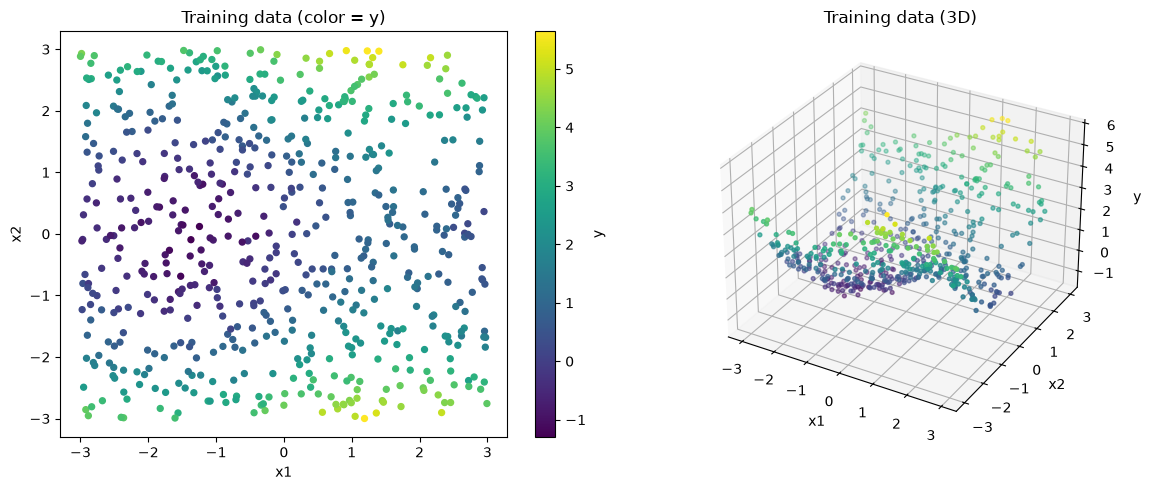

In [11]:
def load(path):
    return np.loadtxt(path, delimiter=",", skiprows=1)
tr, va, te3 = load("data/train.csv"), load("data/val.csv"), load("data/test.csv")
X3_tr, y3_tr, X3_va, y3_va, X3_te = tr[:, :2], tr[:, 2], va[:, :2], va[:, 2], te3[:, :2]
print(X3_tr.shape, X3_va.shape, X3_te.shape)

fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1)
sc = ax.scatter(X3_tr[:, 0], X3_tr[:, 1], c=y3_tr, cmap="viridis", s=18)
plt.colorbar(sc, ax=ax, label="y"); ax.set(xlabel="x1", ylabel="x2", title="Training data (color = y)")
ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.scatter(X3_tr[:, 0], X3_tr[:, 1], y3_tr, c=y3_tr, cmap="viridis", s=8)
ax.set(xlabel="x1", ylabel="x2", zlabel="y", title="Training data (3D)")
plt.tight_layout(); plt.show()

The response is a smooth function over $[-3, 3]^2$: a valley around $(x_1, x_2) \approx (-1.5, 0)$ where $y \approx -1$, rising to $y \approx 5$ near the top and bottom edges at $x_1 \approx 1.5$. It looks like a sinusoid in $x_1$ plus a term that grows with $|x_2|$, with a small amount of noise.

### (b) Random Kitchen Sinks with ridge regression

Features $z_i = (\sin(w_j^\top x_i + b_j), \cos(w_j^\top x_i + b_j))_{j=1}^h$ with $w_j \sim \mathcal{N}(0, I/\sigma^2)$ and $b_j \sim U[0, 2\pi]$, plus an unpenalized intercept. Ridge solution: $\hat\beta = (Z^\top Z + \lambda I)^{-1} Z^\top y$.

I sweep the kernel scale $\sigma$ and keep $h = 500$ (so $D = 2h = 1000$) and $\lambda = 10^{-3}$ fixed.

 sigma  train MSE  val MSE
   0.1     0.0000   1.4668
   0.2     0.0063   1.9505
   0.3     0.0149   0.1064
   0.5     0.0234   0.0595
   1.0     0.0288   0.0455
   2.0     0.0304   0.0381
   3.0     0.0320   0.0369
   5.0     0.0327   0.0362
   7.5     0.0342   0.0363
  10.0     0.0357   0.0372
  15.0     0.0365   0.0376
  20.0     0.0371   0.0387
  30.0     0.0496   0.0556
best sigma: 5.0


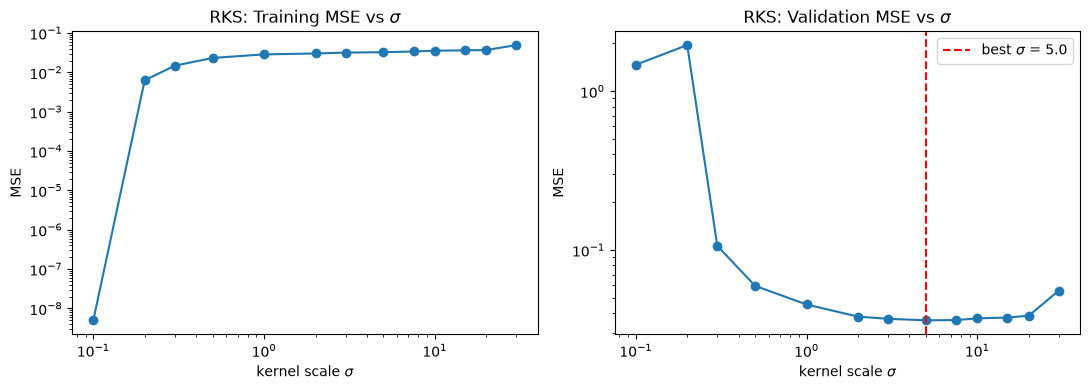

In [12]:
class RandomKitchenSinks:
    def __init__(self, D=1000, sigma=1.0, ridge_lambda=1e-3, seed=0):
        rng = np.random.default_rng(seed)
        self.h = D // 2
        self.W = rng.normal(0, 1 / sigma, size=(2, self.h))
        self.b = rng.uniform(0, 2 * np.pi, size=self.h)
        self.lam = ridge_lambda

    def _features(self, X):
        proj = X @ self.W + self.b
        return np.hstack([np.sin(proj), np.cos(proj), np.ones((len(X), 1))])  # last column = intercept

    def fit(self, X, y):
        Z = self._features(X)
        P = self.lam * np.eye(Z.shape[1]); P[-1, -1] = 0           # do not penalize the intercept
        self.coef_ = np.linalg.solve(Z.T @ Z + P, Z.T @ y)
        return self

    def predict(self, X):
        return self._features(X) @ self.coef_

mse = lambda y, p: np.mean((y - p) ** 2)
sigmas = [0.1, 0.2, 0.3, 0.5, 1.0, 2.0, 3.0, 5.0, 7.5, 10.0, 15.0, 20.0, 30.0]
rks_train, rks_val = [], []
for s in sigmas:
    m = RandomKitchenSinks(sigma=s).fit(X3_tr, y3_tr)
    rks_train.append(mse(y3_tr, m.predict(X3_tr))); rks_val.append(mse(y3_va, m.predict(X3_va)))
best_sigma = sigmas[int(np.argmin(rks_val))]
print(pd.DataFrame({"sigma": sigmas, "train MSE": rks_train, "val MSE": rks_val}).round(4).to_string(index=False))
print("best sigma:", best_sigma)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, vals, name in zip(axes, [rks_train, rks_val], ["Training", "Validation"]):
    ax.plot(sigmas, vals, marker="o"); ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlabel=r"kernel scale $\sigma$", ylabel="MSE", title=f"RKS: {name} MSE vs $\\sigma$")
axes[1].axvline(best_sigma, color="red", ls="--", label=f"best $\\sigma$ = {best_sigma}"); axes[1].legend()
plt.tight_layout(); plt.show()

Small $\sigma$ means large random frequencies $w_j$, so the features oscillate quickly. With $D = 1000$ features and 600 training points the model can then interpolate the training data (training MSE about 0) but generalizes badly (validation MSE above 1). As $\sigma$ grows the features become smoother: training MSE increases slowly while validation MSE falls, until $\sigma$ is so large (30) that the features are too smooth to represent the function and both errors go up. The best validation MSE is at $\sigma = 5$, an interior point of the sweep.

### (c) One-hidden-layer MLP

`Linear(2, d_hidden) → ReLU → Linear(d_hidden, 1)`, full-batch Adam (lr $= 10^{-2}$) for 3,000 steps on MSE. I sweep the hidden width `d_hidden` with all else fixed.

 d_hidden  train MSE  val MSE
        2     0.2882   0.2884
        4     0.2904   0.2910
        8     0.0407   0.0519
       16     0.0323   0.0434
       32     0.0302   0.0414
       64     0.0294   0.0408
      128     0.0288   0.0405
      256     0.0266   0.0401
      512     0.0249   0.0406
best d_hidden: 256


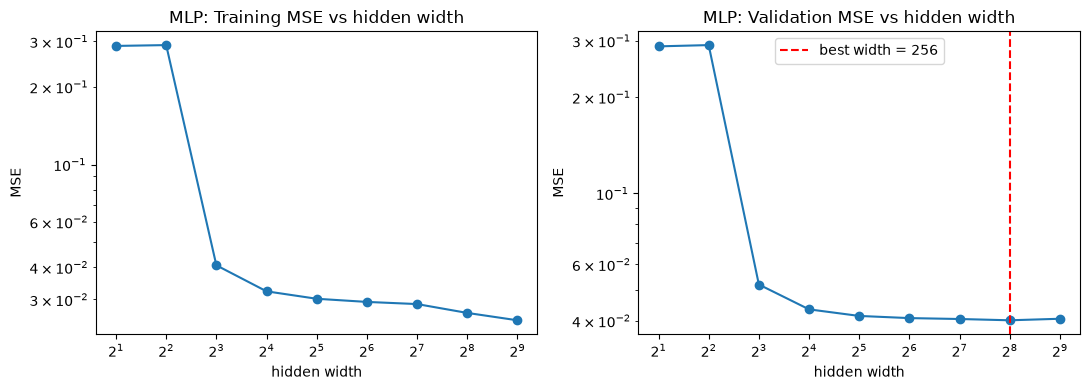

In [13]:
class MLP(nn.Module):
    def __init__(self, d_in=2, d_hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Linear(d_hidden, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)
    def fit(self, X, y, lr=1e-2, steps=3000):
        X, y = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)
        opt = torch.optim.Adam(self.parameters(), lr=lr)
        self.train()
        for _ in range(steps):
            loss = F.mse_loss(self(X), y)
            opt.zero_grad(); loss.backward(); opt.step()
        self.eval()
        return self
    def predict(self, X):
        with torch.no_grad():
            return self(torch.tensor(X, dtype=torch.float32)).numpy()

widths = [2, 4, 8, 16, 32, 64, 128, 256, 512]
mlp_train, mlp_val = [], []
for w in widths:
    torch.manual_seed(SEED)
    m = MLP(d_hidden=w).fit(X3_tr, y3_tr)
    mlp_train.append(mse(y3_tr, m.predict(X3_tr))); mlp_val.append(mse(y3_va, m.predict(X3_va)))
best_width = widths[int(np.argmin(mlp_val))]
print(pd.DataFrame({"d_hidden": widths, "train MSE": mlp_train, "val MSE": mlp_val}).round(4).to_string(index=False))
print("best d_hidden:", best_width)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, vals, name in zip(axes, [mlp_train, mlp_val], ["Training", "Validation"]):
    ax.plot(widths, vals, marker="o"); ax.set_xscale("log", base=2); ax.set_yscale("log")
    ax.set(xlabel="hidden width", ylabel="MSE", title=f"MLP: {name} MSE vs hidden width")
axes[1].axvline(best_width, color="red", ls="--", label=f"best width = {best_width}"); axes[1].legend()
plt.tight_layout(); plt.show()

With only 2 or 4 hidden units the network underfits (both errors about 0.29). From 8 units on it fits the shape, and validation MSE keeps improving slowly up to 256 units. At 512 units training MSE keeps falling while validation MSE goes up slightly, a mild sign of overfitting. The best width by validation MSE is 256.

### (d) Comparison and visualization

RKS (sigma=5.0) validation MSE: 0.0362
MLP (d_hidden=256) validation MSE: 0.0401


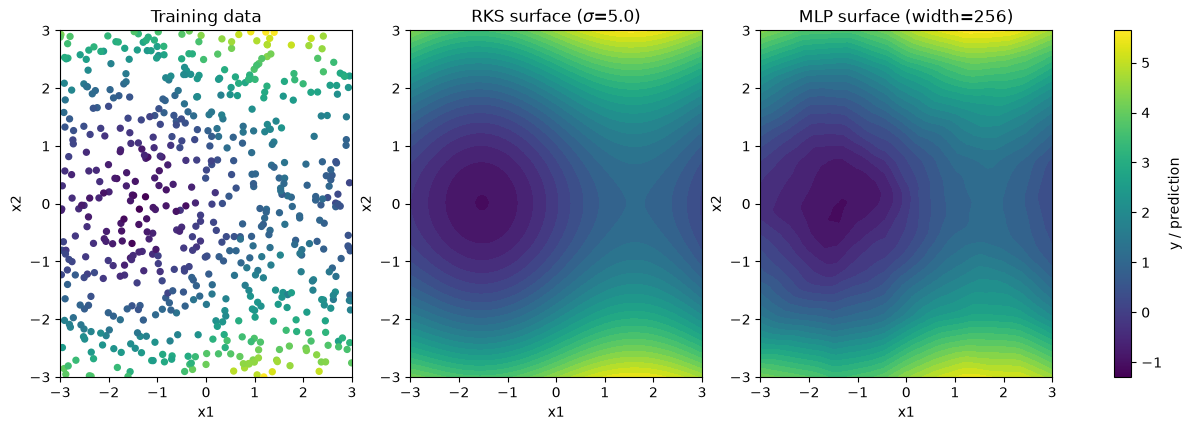

In [14]:
rks_best = RandomKitchenSinks(sigma=best_sigma).fit(X3_tr, y3_tr)
torch.manual_seed(SEED)
mlp_best = MLP(d_hidden=best_width).fit(X3_tr, y3_tr)
print(f"RKS (sigma={best_sigma}) validation MSE: {mse(y3_va, rks_best.predict(X3_va)):.4f}")
print(f"MLP (d_hidden={best_width}) validation MSE: {mse(y3_va, mlp_best.predict(X3_va)):.4f}")

# test predictions, one per row in the order of test.csv
pd.DataFrame({"y_pred": rks_best.predict(X3_te)}).to_csv("rks_test_predictions.csv", index=False)
pd.DataFrame({"y_pred": mlp_best.predict(X3_te)}).to_csv("mlp_test_predictions.csv", index=False)

# fitted surfaces over [-3, 3]^2 (same idea as the provided plot_surface_2d)
g = np.linspace(-3, 3, 200)
G1, G2 = np.meshgrid(g, g)
Xg = np.column_stack([G1.ravel(), G2.ravel()])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
vmin, vmax = y3_tr.min(), y3_tr.max()
sc = axes[0].scatter(X3_tr[:, 0], X3_tr[:, 1], c=y3_tr, s=18, vmin=vmin, vmax=vmax)
axes[0].set_title("Training data")
for ax, model, name in [(axes[1], rks_best, f"RKS surface ($\\sigma$={best_sigma})"),
                        (axes[2], mlp_best, f"MLP surface (width={best_width})")]:
    ax.contourf(G1, G2, model.predict(Xg).reshape(G1.shape), levels=30, vmin=vmin, vmax=vmax)
    ax.set_title(name)
for ax in axes:
    ax.set(xlabel="x1", ylabel="x2", xlim=(-3, 3), ylim=(-3, 3))
fig.colorbar(sc, ax=axes, label="y / prediction")
plt.show()

**Which is better.** On the validation set the RKS model (MSE about 0.036, $\sigma = 5$) does slightly better than the MLP (MSE about 0.040, width 256). Both are close to the noise floor: the best training errors are about 0.03, so neither can improve much further. RKS wins here because the target is a smooth, low-dimensional function, which is exactly what a Gaussian (RBF) kernel approximation is good at. Once $\sigma$ is tuned, the random features cover the right frequency range and ridge regression finds the optimal linear combination in closed form, with no optimization noise. The MLP has to learn its features by gradient descent from only 600 points, and ReLU units build the function out of piecewise-linear pieces, which approximates smooth curvature less efficiently.

**Test predictions** are saved to `rks_test_predictions.csv` and `mlp_test_predictions.csv` (one prediction per row, same order as `test.csv`).

**Fitted surfaces.** Both surfaces reproduce the structure seen in part (a): the valley near $(-1.5, 0)$ and the high values near the top and bottom edges around $x_1 \approx 1.5$. The RKS surface is very smooth, because it is a sum of smooth sinusoids, i.e. an approximation to Gaussian kernel regression. The MLP surface has the same overall shape but shows faint straight creases and slightly polygonal contours (most visible around the valley), because a one-hidden-layer ReLU network is a piecewise-linear function whose pieces are separated by the hyperplanes of its hidden units. Both models filter out the noise rather than chasing individual points.